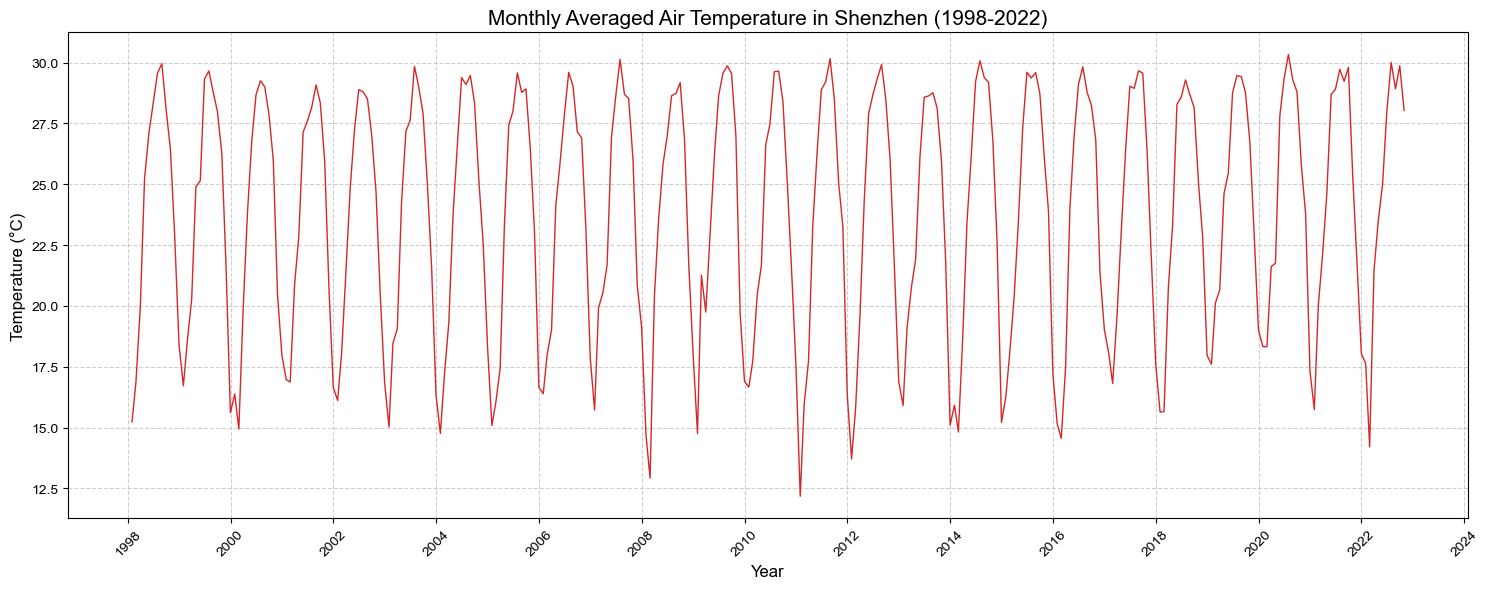

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. 读取数据
df = pd.read_csv('Baoan_Weather_1998_2022.csv', low_memory=False)

# 2. 转换时间格式
df['DATE'] = pd.to_datetime(df['DATE'])

# 3. 清洗 TMP 列
# 强制转换为字符串，并过滤掉缺失值
df['TMP'] = df['TMP'].astype(str)
valid_tmp = df[~df['TMP'].str.contains('9999', na=False) & (df['TMP'] != 'nan')].copy()

# 4. 提取温度，转换浮点数，除以 10（这步如果没有成功，后面就会报你截图里的错）
valid_tmp['Temp_C'] = valid_tmp['TMP'].str.split(',').str[0].astype(float) / 10.0

# 5. 设置时间为索引，按月降采样（Resample）求平均
valid_tmp.set_index('DATE', inplace=True)
monthly_temp = valid_tmp['Temp_C'].resample('ME').mean()

# 6. 画图
plt.figure(figsize=(15, 6))
plt.plot(monthly_temp.index, monthly_temp.values, color='tab:red', linewidth=1)

# 设置标题和标签
plt.title('Monthly Averaged Air Temperature in Shenzhen (1998-2022)', fontsize=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

# 美化X轴
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

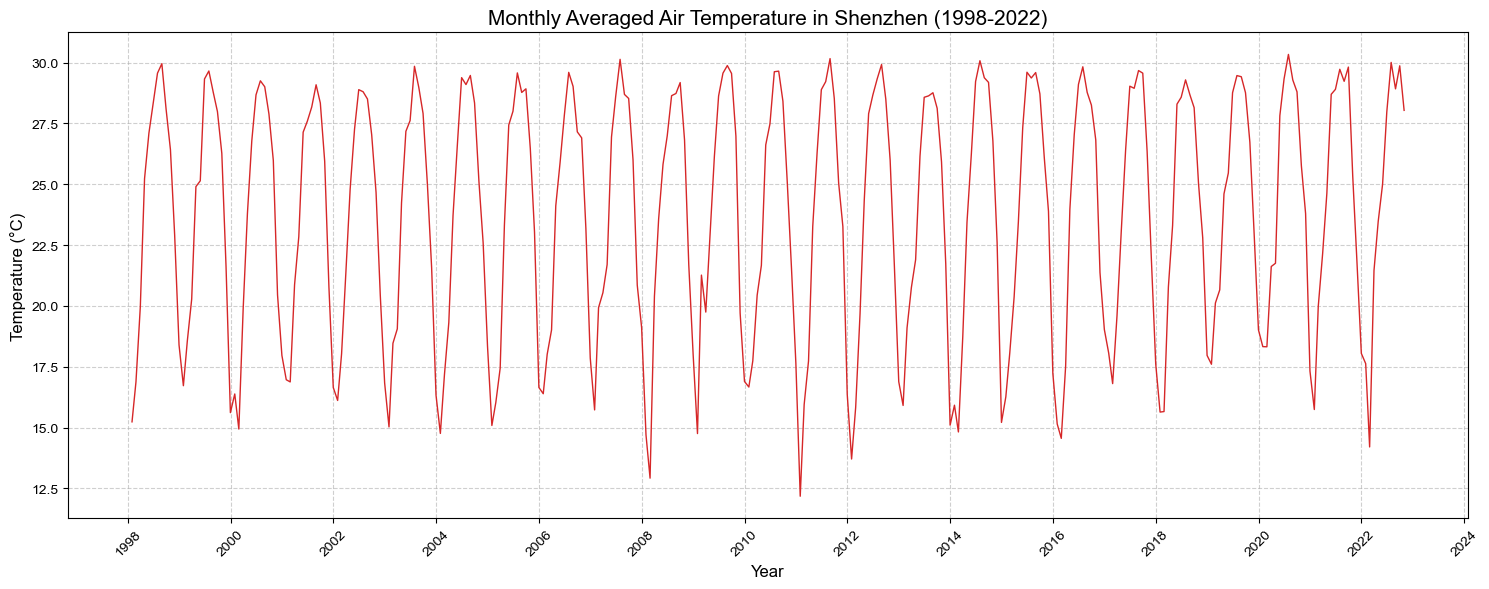

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 读取数据
df = pd.read_csv('Baoan_Weather_1998_2022.csv', low_memory=False)

# 转换时间格式,将日期列转换成可解析的日期格式
df['DATE'] = pd.to_datetime(df['DATE'])

# 清洗 TMP 列的数据
df['TMP'] = df['TMP'].astype(str)  #首先将这一列全部转换为字符串格式，便于清洗；否则是数值型与字符串型的混杂，运行会报错
valid_tmp = df[
    (~df['TMP'].str.contains('9999', na=False)) &  #~为取反的意思，即取有效值；na=False以为遇到空值就跳过，否则会报错
    (df['TMP'] != 'nan') & 
    (df['TMP'].str.split(',').str[1].str.strip() == '1')  #根据NOAA的手册，TMP列由逗号隔开，第二列的数字代表数据测量质量，1为通过控制检查，为保证严谨性，只用表示为1的数据计算
].copy()  #copy()意为将筛选获得的数据复制保存为一个独立的表格，在新表格操作不会影响原表格，新表格为valid_tmp

# 提取温度
valid_tmp['Temp_C'] = valid_tmp['TMP'].str.split(',').str[0].astype(float) / 10.0  #.str.split(',')以为将字符串按照，分成两列，取第一列，根据手册，缩放因子是10，转换成浮点型后除以十得到真实的摄氏温度

# 5. 设置时间为索引，按月降采样求平均
valid_tmp.set_index('DATE', inplace=True)  #将日期列设置为索引，使用.set_index()的方法，inplace=True以为直接修改表格本身，不需要再赋值新变量创建表格。
monthly_temp = valid_tmp['Temp_C'].resample('ME').mean()  #.resample('ME')用重采样的方法，ME为月末，即将逐小时数据按照月份封装起来,最后求月均值，保存到一张表格里，日期是索引，月均值是values

# 6. 画图
plt.figure(figsize=(15, 6))
plt.plot(monthly_temp.index, monthly_temp.values, color='blue', linewidth=1)

# 设置标题和标签
plt.title('Monthly Averaged Air Temperature in Shenzhen (1998-2022)', fontsize=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

#对图表的可视化进行一下美化
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))  #.gca()方法是获取当前的坐标轴，设置坐标轴只显示年份，否则会很难看
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))  #设置年份的显示步长为2
plt.xticks(rotation=45)  #x轴坐标标签旋转45度

plt.tight_layout() #紧凑布局，防止图像和文字超出
plt.show()